# Nonlinear embedding fusion: kernels, DeepSets and gates

This executable tutorial uses **synthetic data only**. Real LINCS results are in the reproducibility repository's `small_molecule/lincs/fusion/notebooks/` folder. Neural fusion needs `pip install "embpy[torch]"`.

All views describe the same entities. We hold out connected groups before fitting anything, including preprocessing. Neural models learn from regression targets; kernel fusion does not. Fixed epoch candidates are selected in grouped training folds, with no internal validation split.


In [1]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from embpy.io.result import EmbeddingProvenance, EmbeddingResult
from embpy.tl.fusion import (
    KernelFusion,
    DeepSetsFusion,
    GatedFusion,
    ConcatMLPFusion,
    PCAFusion,
    FusionConfig,
    subset_views,
)
from embpy.tl.benchmark import benchmark_fusion

rng = np.random.default_rng(21)
ids = tuple(f"compound_{i}" for i in range(72))
latent = rng.normal(size=(72, 4))
matrices = {
    "fingerprint": (latent @ rng.normal(size=(4, 16)) > 0).astype(float),
    "language": latent @ rng.normal(size=(4, 12)) + rng.normal(size=(72, 12)) * 0.2,
}
views = {
    name: EmbeddingResult(X, ids, "molecule", "tutorial_id", EmbeddingProvenance("synthetic:" + name))
    for name, X in matrices.items()
}
y = pd.DataFrame(np.column_stack([latent[:, 0] * latent[:, 1], np.sin(latent[:, 2]), latent[:, 3]]), index=ids)
groups = pd.Series([f"group_{i // 2}" for i in range(72)], index=ids)
train, test = ids[:54], ids[54:]
training, held_out = subset_views(views, train), subset_views(views, test)

## A kernel for each view

The weighted kernel sum uses raw nonnegative fingerprints with Tanimoto and L2-normalized dense features with RBF. Its Nyström landmarks and RBF bandwidth are learned only from training compounds. This is a fixed-weight kernel combination, **not supervised multiple-kernel learning**. The output is a low-rank kernel feature map, not kernel PCA.


In [2]:
kernel = KernelFusion(
    n_components=8,
    n_landmarks=32,
    kernels={"fingerprint": "tanimoto", "language": "rbf"},
    normalization={"fingerprint": "none", "language": "l2"},
    random_state=0,
)
kernel.fit(training)
new_kernel_features = kernel.transform(held_out)
assert new_kernel_features.entity_ids == test
assert set(kernel.landmark_ids_).issubset(train)
print("Held-out kernel features:", new_kernel_features.matrix.shape)
print("Training-fitted bandwidth:", kernel.gammas_["language"])

Held-out kernel features: (18, 8)
Training-fitted bandwidth: 0.4943013372525654


## Supervised nonlinear representations

DeepSets uses named view adapters, shared processing, mean pooling and a nonlinear output map. Gated fusion learns per-compound softmax weights for the projected views. Both require the same known views at inference; dictionary order may change. The gate weights are diagnostics, not causal importance.

An indexed target table is joined by ID. `predict` uses the training head, while `transform` returns features for a separately evaluated downstream readout. Access to targets is an extra source of supervision, so the benchmark also includes a concatenation-MLP and a single-view MLP control.


In [3]:
deep = DeepSetsFusion(8, hidden_dim=24, epochs=40, learning_rate=0.005, random_state=3)
gated = GatedFusion(8, hidden_dim=24, epochs=40, learning_rate=0.005, random_state=3)
deep.fit(training, y.loc[list(train)])
gated.fit(training, y.loc[list(train)].iloc[::-1])  # ID alignment, not row position
weights = gated.view_weights(held_out)
assert np.allclose(weights.sum(axis=1), 1)
assert gated.transform(held_out).matrix.shape == (18, 8)
print("Training loss, first/last epoch:", gated.loss_curve_[0], gated.loss_curve_[-1])
weights.head()

Training loss, first/last epoch: 1.036543607711792 0.5154438018798828


,fingerprint,language
compound_54,0.290106,0.709894
compound_55,0.364931,0.635068
compound_56,0.273088,0.726912
compound_57,0.360708,0.639292
compound_58,0.416578,0.583422


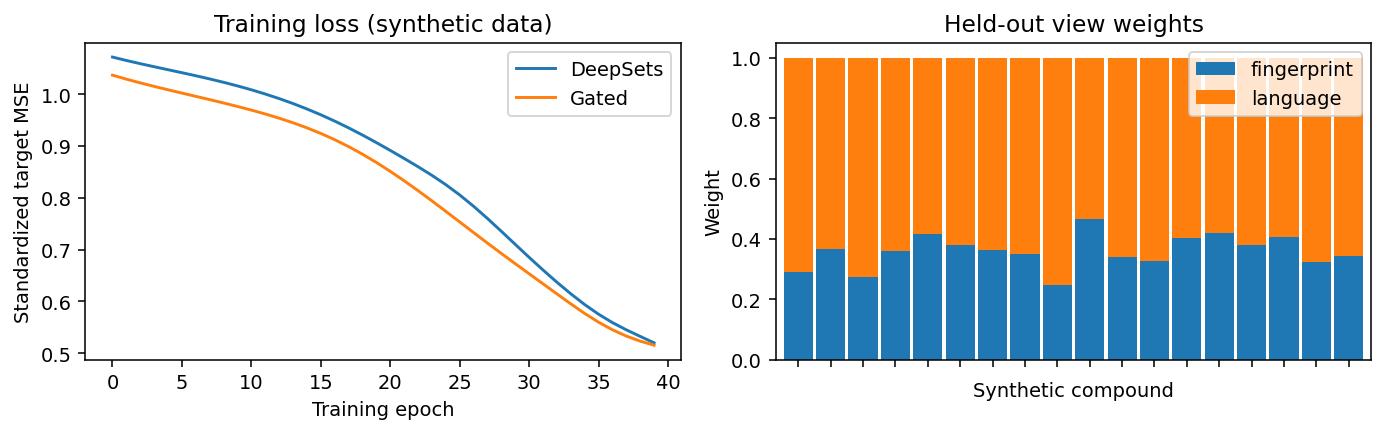

In [4]:
from io import BytesIO
from IPython.display import Image, display
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(deep.loss_curve_, label="DeepSets")
axes[0].plot(gated.loss_curve_, label="Gated")
axes[0].set(xlabel="Training epoch", ylabel="Standardized target MSE", title="Training loss (synthetic data)")
axes[0].legend()
weights.plot.bar(stacked=True, ax=axes[1], legend=True, width=0.9)
axes[1].set(title="Held-out view weights", xlabel="Synthetic compound", ylabel="Weight")
axes[1].set_xticklabels([])
fig.tight_layout()
# Explicit image output also works on headless Slurm nodes (Agg backend).
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Grouped nested evaluation

The adapter forwards **training targets only** into supervised fusion. Every candidate is fitted afresh within the inner folds. The neural epoch grid is an external training-fold choice; outer-test targets cannot affect its selection. Equal output width is not equal parameter count, so both widths and trainable parameter counts are reported. The tiny settings below illustrate the API, not a tuned scientific result.


In [5]:
small = {"n_components": 4, "hidden_dim": 12, "epochs": 3, "pre_components": 6, "random_state": 0}
configs = {
    "pca": PCAFusion(4),
    "kernel": clone(kernel).set_params(n_components=4, n_landmarks=16),
    "deepsets": FusionConfig(DeepSetsFusion(**small), param_grid={"epochs": [3, 6]}),
    "gated": FusionConfig(GatedFusion(**small), param_grid={"epochs": [3, 6]}),
    "concat_mlp": FusionConfig(ConcatMLPFusion(**small), param_grid={"epochs": [3, 6]}),
    "single_mlp": FusionConfig(ConcatMLPFusion(**small), views=("fingerprint",), param_grid={"epochs": [3, 6]}),
}
result = benchmark_fusion(
    views, y, fusions=configs, groups=groups, cv=3, seeds=(0,), single_n_components=4, param_grid={"alpha": [0.1, 10.0]}
)
for _, split in result.splits.groupby(["seed", "fold"]):
    assert not set(split.query("partition == 'train'").group) & set(split.query("partition == 'test'").group)
result.scores.groupby("configuration")[["pearson", "mse", "output_dim", "trainable_parameters"]].mean().round(4)

,pearson,mse,output_dim,trainable_parameters
configuration,,,,
concat_mlp,0.5246,0.5764,4.0,223.0
deepsets,0.2751,0.6719,4.0,391.0
gated,0.2967,0.6676,4.0,404.0
kernel,0.6521,0.4810,4.0,0.0
pca,0.7999,0.3954,4.0,0.0
single:fingerprint,0.7217,0.4188,4.0,0.0
single:language,0.8002,0.4026,4.0,0.0
single_mlp,0.4201,0.5873,4.0,151.0


## Serialization and inference

Models are stored on CPU. Loading a fitted neural model requires PyTorch, but importing `embpy.tl.fusion` and using kernel/linear methods does not. Only load trusted joblib files.


In [6]:
import joblib
import tempfile
from pathlib import Path

with tempfile.TemporaryDirectory() as directory:
    path = Path(directory) / "gated.joblib"
    joblib.dump(gated, path)
    restored = joblib.load(path)
    np.testing.assert_allclose(restored.transform(held_out).matrix, gated.transform(held_out).matrix)
print("Round trip verified; all fitted operators use training entities only.")

Round trip verified; all fitted operators use training entities only.
